# 06. Optimizing over trained Gaussian processes

Schweidtmann et al. [schweidtmann2021deterministic] (arXiv:2005.10902) solve
optimization problems with trained Gaussian processes (GPs) embedded, to a
certified global optimum. Their main point is the *reduced-space* (RS)
formulation: the GP mean $m_D(x)$ and variance $k_D(x)$ are explicit
functions of the inputs, so branch and bound should branch only on $x$ and
propagate McCormick relaxations through the prediction formulas. The
alternative *full-space* (FS) formulation, with one variable and one equality
constraint per kernel evaluation, grows with the number of training points
$N$ and was up to 778 times slower in MAiNGO at $N=250$.

jaxglobal works in reduced space by construction: the objective is a JAX
function, and its jaxpr is relaxed as it stands. A GP prediction written in
`jax.numpy` is already an RS model. This notebook repeats the paper's case
studies in that style:

1. minimizing the GP mean of the peaks function, and how the solve scales with $N$ and the kernel;
2. globally maximizing the acquisition functions LCB, EI and PI, including PI without a margin;
3. a chance-constrained problem with two GPs embedded;
4. a short Bayesian-optimization loop that runs branch and bound on the acquisition function at every step.

The paper's chemical datasets (N-benzylation, layer-by-layer membranes) are
not public in a form we can load here, so case 3 uses a synthetic two-output
process with the same structure. The membrane case also needs an integer
variable (number of layers), which jaxglobal does not support.

Like the paper, jaxglobal relaxes each kernel as one convex, decreasing
function of the squared distance (`jaxglobal.kernels`, see below). It has
no hand-derived envelopes for the Gaussian PDF/CDF or EI: those come from
McCormick composition, the automatic αBB rule for `erf`, and the univariate
grid envelopes. The tolerances are the paper's: absolute and relative gap
$10^{-3}$.

In [1]:
import os
import pathlib
import sys
import time

os.environ.setdefault("RUST_LOG", "warn")  # keep the local NLP solver's info messages out of the output
ROOT = pathlib.Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT))

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize as sp_minimize
from scipy.stats import qmc

from jaxglobal import kernels, minimize
from jaxglobal.gp import expected_improvement, gp_std, probability_of_improvement

INK, MUTED, BLUE, ORANGE, AQUA, YELLOW = "#1a1a19", "#77766f", "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.6, "figure.dpi": 110})
TOL = dict(abs_tol=1e-3, rel_tol=1e-3)

## A Gaussian process in a few lines of JAX

Following the paper, the kernels are written as functions of the weighted
squared distance $d = (x-x')^\top \Lambda (x-x')$ rather than of
$r = \sqrt d$. The four Matérn kernels are

$$ k_{1/2}(d) = e^{-\sqrt d},\quad k_{3/2}(d) = (1+\sqrt{3d})\,e^{-\sqrt{3d}},\quad
   k_{5/2}(d) = \left(1+\sqrt{5d}+\tfrac{5}{3}d\right)e^{-\sqrt{5d}},\quad
   k_{SE}(d) = e^{-d/2}. $$

Inputs are scaled to $[-1,1]$ and outputs to zero mean and unit variance.
The hyperparameters (length scales, signal variance, noise variance) are
fitted by maximizing the log marginal likelihood from ten random starts
(the paper uses a MAP estimate with a log-normal prior; on these data sets the
difference is small). The prediction is the usual

$$ m_D(x) = k_{x,X}\,\alpha, \qquad k_D(x) = \sigma_f^2 - k_{x,X} K^{-1} k_{X,x},
   \qquad \alpha = K^{-1} y, $$

with $K = K_{X,X} + \sigma_n^2 I$. Once trained, $\alpha$ and $K^{-1}$ are
constants, and `mean` and `std` below are the functions jaxglobal sees.

**How the kernel is written matters.** Written in `jnp`, the Matérn 5/2
kernel $(1+\sqrt{5d}+\tfrac53 d)\,e^{-\sqrt{5d}}$ is a product of a
polynomial in $\sqrt d$ and an exponential, and McCormick relaxes the two
factors separately: a term whose true range is $[0,1]$ gets an enclosure up to
about 200 wide on a large box. Its automatic second derivative also goes
through $\sqrt d$, so the αBB Hessian is infinite at every training point.
`jaxglobal.kernels` provides the four kernels as JAX primitives instead. Each
is one convex, nonincreasing function of $d$, so its relaxation is the
envelope used by the paper, and its derivatives are primitives too, so αBB
gets a finite Hessian for Matérn 5/2 and SE. The values and derivatives are
the same as the formulas'. Below, the GP is trained with the `jnp` formulas
(`PLAIN`) and predicts with the primitives; `primitive=False` predicts with
the formulas, for comparison.

**The standard deviation needs more than the kernel.** $k_D(x) =
\sigma_f^2 - k_{x,X}K^{-1}k_{X,x}$ is a quadratic form in the kernel vector,
and any bound computed through $K^{-1}$ inherits its conditioning (about
1/noise). `jaxglobal.gp.gp_std` is a primitive with the same value whose
relaxation uses the GP's own structure: the quadratic form as a sum of
squares $\|W^\top k\|^2$ ($K^{-1} = WW^\top$), and a Lipschitz bound that
holds because the posterior is itself a Gaussian process,
$|\sigma(x)-\sigma(c)| \le \mathrm{sd}_{\text{prior}}(f(x)-f(c))
= \sqrt{2\sigma_f^2(1-k(d(x,c)))}$, which does not involve $K^{-1}$ at all.

In [2]:
PLAIN = {
    "matern12": lambda d: jnp.exp(-jnp.sqrt(d)),
    "matern32": lambda d: (1 + jnp.sqrt(3 * d)) * jnp.exp(-jnp.sqrt(3 * d)),
    "matern52": lambda d: (1 + jnp.sqrt(5 * d) + 5 * d / 3) * jnp.exp(-jnp.sqrt(5 * d)),
    "se": lambda d: jnp.exp(-d / 2),
}
KERNELS = kernels.KERNELS  # the same four functions of d, as primitives


class GP:
    """Exact GP regression with a Matérn/SE kernel, fitted by maximum marginal likelihood."""

    def __init__(self, X, y, lo, hi, kernel="matern52", noise=(1e-6, 1e-2), seed=0, primitive=True):
        self.lo, self.hi = np.asarray(lo, float), np.asarray(hi, float)
        self.k = PLAIN[kernel]  # training
        Xs = self.scale(np.asarray(X, float))
        self.ym, self.ys = float(np.mean(y)), float(np.std(y))
        yt = (np.asarray(y, float) - self.ym) / self.ys
        n, dim = Xs.shape

        def gram(th):
            lam, sf2, sn2 = jnp.exp(th[:dim]), jnp.exp(th[dim]), jnp.exp(th[dim + 1])
            d = (((Xs[:, None, :] - Xs[None, :, :]) / lam) ** 2).sum(-1)
            # 1e-30 keeps the derivative of sqrt(d) finite on the diagonal during training
            return sf2 * self.k(d + 1e-30) + (sn2 + 1e-8) * jnp.eye(n)

        def nll(th):
            L = jnp.linalg.cholesky(gram(th))
            a = jax.scipy.linalg.cho_solve((L, True), yt)
            return 0.5 * yt @ a + jnp.log(jnp.diag(L)).sum()

        vg = jax.jit(jax.value_and_grad(nll))
        bounds = [(-4.0, 2.0)] * dim + [(-3.0, 3.0), tuple(np.log(noise))]
        rng = np.random.default_rng(seed)
        best = None
        for _ in range(10):
            th0 = [rng.uniform(a, b) for a, b in bounds]
            r = sp_minimize(lambda t: [np.asarray(v, float) for v in vg(t)], th0, jac=True,
                            method="L-BFGS-B", bounds=bounds)
            if np.isfinite(r.fun) and (best is None or r.fun < best.fun):
                best = r
        th = best.x
        Kx = np.asarray(gram(th))
        self.lam, self.sf2, self.sn2 = np.exp(th[:dim]), float(np.exp(th[dim])), float(np.exp(th[dim + 1]))
        self.Xs, self.alpha, self.Kinv = Xs, np.linalg.solve(Kx, yt), np.linalg.inv(Kx)
        self.k = KERNELS[kernel] if primitive else PLAIN[kernel]  # prediction: what jaxglobal relaxes
        self.kernel, self.primitive = kernel, primitive

    def scale(self, x):
        return 2 * (x - self.lo) / (self.hi - self.lo) - 1

    def kvec(self, x):
        d = (((self.scale(x) - self.Xs) / self.lam) ** 2).sum(-1)
        return self.sf2 * self.k(d)

    def mean(self, x):
        return self.ym + self.ys * self.kvec(x) @ self.alpha

    def std(self, x):
        if self.primitive:  # same value; relaxed with the GP's structure (see below)
            return self.ys * gp_std(self.scale(x), self.Xs, self.lam, self.Kinv, self.sf2, kernel=self.kernel)
        k = self.kvec(x)
        var = self.sf2 - k @ self.Kinv @ k
        return self.ys * jnp.sqrt(jnp.maximum(var, 1e-12))  # variance can round to slightly below 0 at the data

## 1. Minimizing the GP mean of the peaks function

The paper's first case trains GPs on Latin-hypercube samples of the peaks
function on $[-3,3]^2$,

$$ f(x_1,x_2) = 3(1-x_1)^2 e^{-x_1^2-(x_2+1)^2} - 10\left(\tfrac{x_1}{5}-x_1^3-x_2^5\right)e^{-x_1^2-x_2^2}
   - \tfrac13 e^{-(x_1+1)^2-x_2^2}, $$

which has several local minima and a global minimum $f \approx -6.551$ at
$x^* \approx (0.228, -1.626)$, and then minimizes the GP mean.

The objective handed to jaxglobal is `gp.mean`, nothing more. For each
solve we also evaluate the mean on a $601\times601$ grid as an independent
check of the certificate.

In [3]:
def peaks(x):
    x1, x2 = x[..., 0], x[..., 1]
    return (3 * (1 - x1) ** 2 * jnp.exp(-x1**2 - (x2 + 1) ** 2)
            - 10 * (x1 / 5 - x1**3 - x2**5) * jnp.exp(-x1**2 - x2**2)
            - jnp.exp(-(x1 + 1) ** 2 - x2**2) / 3)


LO, HI = np.array([-3.0, -3.0]), np.array([3.0, 3.0])
XSTAR = np.array([0.228, -1.626])
g = np.linspace(-3, 3, 601)
GRID = jnp.array(np.stack(np.meshgrid(g, g), -1).reshape(-1, 2))


def lhs(n, seed=0, lo=LO, hi=HI):
    return qmc.scale(qmc.LatinHypercube(d=len(lo), seed=seed).random(n), lo, hi)


def solve(f, lo, hi, **kw):
    t = time.perf_counter()
    r = minimize(f, lo, hi, **TOL, **kw)
    return r, time.perf_counter() - t


X = lhs(50)
gp = GP(X, peaks(X), LO, HI)
r, t = solve(gp.mean, LO, HI)
print(r)
grid_min = float(jax.vmap(gp.mean)(GRID).min())
print(f"grid minimum of the GP mean: {grid_min:.5f}")

Result(status='optimal', fun=-4.0287544, lower_bound=-4.0303826, gap=1.63e-03, x=[ 0.422341 -1.762596], nodes=425, iterations=16, time=9.15s)


grid minimum of the GP mean: -4.02869


The certificate brackets the grid minimum: the found value matches the grid
value (up to the grid spacing) and the lower bound is below it.
With 50 points the GP puts its minimum about 0.24 from the true minimizer
of peaks, but predicts −4.03 there instead of −6.55: the deep, narrow well
is not yet resolved. That is a modelling question, not an optimization one:
jaxglobal answers "what does *this* GP predict as the best point", with a
proof.

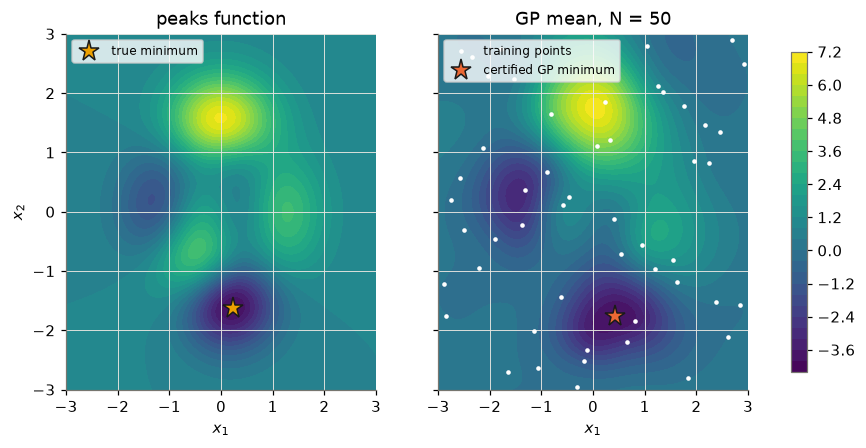

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
gg = np.linspace(-3, 3, 161)
G2 = jnp.array(np.stack(np.meshgrid(gg, gg), -1))
for ax, fun, title in ((axes[0], peaks, "peaks function"), (axes[1], jax.vmap(jax.vmap(gp.mean)), "GP mean, N = 50")):
    cs = ax.contourf(gg, gg, np.asarray(fun(G2)), levels=30, cmap="viridis")
    ax.set_title(title)
    ax.set_xlabel("$x_1$")
axes[1].plot(*X.T, ".", color="white", ms=4, label="training points")
axes[1].plot(*r.x, "*", color=ORANGE, ms=14, mec=INK, label="certified GP minimum")
axes[0].plot(*XSTAR, "*", color=YELLOW, ms=14, mec=INK, label="true minimum")
axes[0].set_ylabel("$x_2$")
for ax in axes:
    ax.legend(loc="upper left", fontsize=8)
fig.colorbar(cs, ax=axes, shrink=0.9)
plt.show()

### Kernel primitives against the `jnp` formula

The same trained GPs, minimized once with the `jnp` formula in the
prediction and once with `jaxglobal.kernels`:

In [5]:
rows = []
for n in (50, 200):
    X = lhs(n)
    for prim in (False, True):
        gpc = GP(X, peaks(X), LO, HI, primitive=prim)
        r, t = solve(gpc.mean, LO, HI)
        rows.append(dict(N=n, kernel="kernels.matern52" if prim else "jnp formula", status=r.status, found=r.fun,
                         lower_bound=r.lower_bound, nodes=r.nodes, iterations=r.iterations, time_s=t))
pd.DataFrame(rows)

,N,kernel,status,found,lower_bound,nodes,iterations,time_s
0,50,jnp formula,optimal,-4.028754,-4.032496,3489,22,10.758503
1,50,kernels.matern52,optimal,-4.028754,-4.030383,425,16,1.439675
2,200,jnp formula,optimal,-6.549043,-6.555553,23191,98,77.809492
3,200,kernels.matern52,optimal,-6.549043,-6.554578,2343,19,8.318314


Same certified optimum, about ten times fewer nodes: 3,489 → 425 at
$N = 50$, and 23,191 → 2,343 at $N = 200$, where the iterations drop from 98
to 19. Nothing else changed: same GP, same solver options. The rest of the
notebook uses the primitives.

### Scaling with the number of training points

In the reduced space the number of branching variables stays at 2 for every
$N$. What grows is the work per node: each kernel vector has $N$ entries,
and each entry has its own relaxation. The paper's RS solve time grew
roughly like $N^{1.16}$ in MAiNGO. Here is the same experiment for one
data set per size (the paper used 50 repetitions per size).

In [6]:
rows = []
for n in (20, 50, 100, 200, 400):
    X = lhs(n)
    gpn = GP(X, peaks(X), LO, HI)
    r, t = solve(gpn.mean, LO, HI)
    gm = float(jax.vmap(gpn.mean)(GRID).min())
    rows.append(dict(N=n, status=r.status, found=r.fun, lower_bound=r.lower_bound, grid_min=gm,
                     dist_to_true=float(np.linalg.norm(r.x - XSTAR)), nodes=r.nodes, time_s=t))
scaling = pd.DataFrame(rows)
scaling

,N,status,found,lower_bound,grid_min,dist_to_true,nodes,time_s
0,20,optimal,-2.435344,-2.436648,-2.435258,2.894146,89,5.246320
1,50,optimal,-4.028754,-4.030383,-4.028686,0.237544,425,1.098609
2,100,optimal,-5.950057,-5.955224,-5.949974,0.141806,665,6.117430
3,200,optimal,-6.549043,-6.554578,-6.548745,0.001764,2343,4.244148
4,400,optimal,-6.551708,-6.557948,-6.551415,0.000438,5859,15.857177


Every solve is certified, and in every row the lower bound is below the
grid minimum and the found value matches it. As $N$ grows, the GP minimum
moves to the true minimizer of peaks: at 200 points it is 0.002 away and
predicts −6.549; at 400 points, −6.5517 (the literature value is −6.551).

The node count still grows faster than $N$, roughly like $N^{1.4}$ (89
nodes at $N = 20$, 5,859 at $N = 400$), with two branching variables
throughout. Each term is now relaxed by its envelope, so what remains is the
sum: the weights $\alpha_i$ grow with $N$ and have mixed signs, and a
term-by-term relaxation cannot see the cancellation between them. αBB, which
works on the whole sum, recovers it on small boxes. With the `jnp` formula
the same series took 1,079 to 91,289 nodes and several minutes at
$N = 400$; now the largest solve takes about 18 s. The times include JIT
compilation, which happens once for every new $N$, since the shapes change.

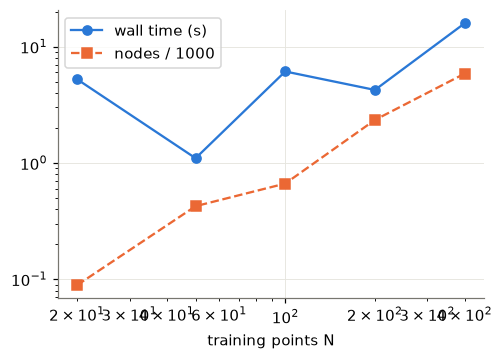

In [7]:
fig, ax = plt.subplots(figsize=(5, 3.4))
ax.loglog(scaling.N, scaling.time_s, "o-", color=BLUE, label="wall time (s)")
ax.loglog(scaling.N, scaling.nodes / 1000, "s--", color=ORANGE, label="nodes / 1000")
ax.set_xlabel("training points N")
ax.legend()
plt.show()

### Kernels

The paper reports its scaling for $k_{5/2}$ and says the other kernels
behave similarly. With 50 points, the four kernels give different GPs, and
so different minima, and all of them are certified.

In [8]:
X = lhs(50)
rows = []
for name in KERNELS:
    gpk = GP(X, peaks(X), LO, HI, kernel=name)
    r, t = solve(gpk.mean, LO, HI)
    gm = float(jax.vmap(gpk.mean)(GRID).min())
    rows.append(dict(kernel=name, status=r.status, found=r.fun, lower_bound=r.lower_bound,
                     grid_min=gm, nodes=r.nodes, time_s=t))
pd.DataFrame(rows)

,kernel,status,found,lower_bound,grid_min,nodes,time_s
0,matern12,optimal,-3.611721,-3.615311,-3.597560,123,4.552130
1,matern32,optimal,-3.721253,-3.724648,-3.721181,429,2.917693
2,matern52,optimal,-4.028754,-4.030383,-4.028686,425,0.903778
3,se,optimal,-4.868505,-4.871921,-4.868467,439,2.980574


With the primitives the four kernels need similar node counts (123 to 439).
For the two kernels whose `jnp` formulas are a single monotone function of
$d$, $k_{1/2} = e^{-\sqrt d}$ and $k_{SE} = e^{-d/2}$, the formula was
already relaxed this well. $k_{3/2}$ gains most from the envelope: 1,917
nodes with the formula, 429 now. It gets no αBB, though: its second
derivative, like that of $k_{1/2}$, is infinite at $d = 0$, so only
$k_{5/2}$ and $k_{SE}$ are marked smooth.

## 2. Acquisition functions

In Bayesian optimization the next experiment maximizes an acquisition
function of $\mu = m_D(x)$ and $\sigma = \sqrt{k_D(x)}$. Acquisition
functions are multimodal (they are near zero at every data point and
bulge between them), which is why the paper argues for solving them
globally. With $f_{\min}$ the best observed value,

$$ \mathrm{LCB} = \mu - \kappa\sigma,\qquad
   \mathrm{PI} = \Phi\!\left(\frac{f_{\min}-\xi-\mu}{\sigma}\right),\qquad
   \mathrm{EI} = (f_{\min}-\mu)\,\Phi(z) + \sigma\,\phi(z),\ z = \frac{f_{\min}-\mu}{\sigma}. $$

We minimize LCB and $-$PI, $-$EI. Written as formulas, EI and PI are
relaxed piece by piece ($\Phi$, $\phi$, the division), which loses most of
their structure. `jaxglobal.gp` provides them as primitives with the same
values, relaxed as what they are, in the spirit of the paper's dedicated
relaxations. EI is the perspective $\sigma\,\psi((f_{\min}-\mu)/\sigma)$ of
the convex $\psi(z) = z\Phi(z)+\phi(z)$, so it is jointly convex in
$(\mu,\sigma)$ and monotone; its concave overestimator is the concave
envelope over the $(\mu,\sigma)$ box. PI is monotone in $\mu$ and in
$\sigma$ on either side of $\mu = f_{\min}-\xi$, and its relaxation
combines a bound from that monotonicity with the exact envelopes of the
sigmoid $\Phi$.

The GP is the 20-point peaks model, so there is plenty to explore.

In [9]:
X20 = lhs(20)
y20 = np.asarray(peaks(X20))
gp20 = GP(X20, y20, LO, HI)
fmin = float(y20.min())


def lcb(x, kappa=2.0):
    return gp20.mean(x) - kappa * gp20.std(x)


def neg_ei(x):
    return -expected_improvement(gp20.mean(x), gp20.std(x), fmin)


def neg_pi(x, xi=0.1 * gp20.ys):
    return -probability_of_improvement(gp20.mean(x), gp20.std(x), fmin - xi)


rows, sols = [], {}
for name, f in (("LCB (κ=2)", lcb), ("−EI", neg_ei), ("−PI (ξ = 0.1σ_y)", neg_pi)):
    r, t = solve(f, LO, HI, time_limit=300)
    sols[name] = (f, r)
    gm = float(jax.vmap(f)(GRID).min())
    rows.append(dict(acquisition=name, status=r.status, found=r.fun, lower_bound=r.lower_bound,
                     grid_min=gm, x1=r.x[0], x2=r.x[1], nodes=r.nodes, time_s=t))
pd.DataFrame(rows)

,acquisition,status,found,lower_bound,grid_min,x1,x2,nodes,time_s
0,LCB (κ=2),optimal,-4.328816,-4.333007,-4.328794,-0.309330,-2.022102,333,7.444542
1,−EI,optimal,-0.341161,-0.342127,-0.341145,-0.120658,-1.956416,765,13.042518
2,−PI (ξ = 0.1σ_y),optimal,-0.440400,-0.441300,-0.440254,-1.675657,0.595217,451,17.508337


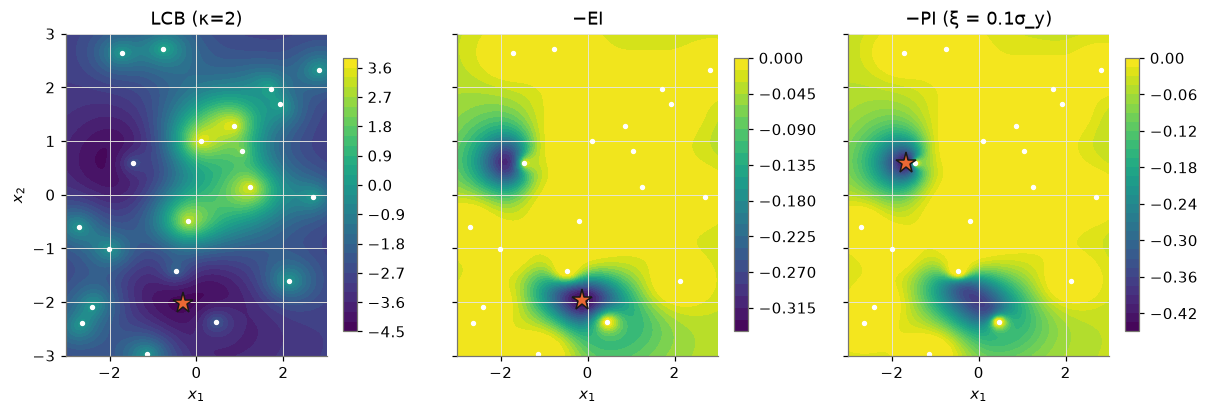

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (name, (f, r)) in zip(axes, sols.items()):
    v = np.asarray(jax.vmap(jax.vmap(f))(G2))
    cs = ax.contourf(gg, gg, v, levels=30, cmap="viridis")
    ax.plot(*X20.T, ".", color="white", ms=5)
    ax.plot(*r.x, "*", color=ORANGE, ms=14, mec=INK)
    ax.set_title(name)
    ax.set_xlabel("$x_1$")
    fig.colorbar(cs, ax=ax, shrink=0.85)
axes[0].set_ylabel("$x_2$")
plt.show()

The three acquisition functions pick different points. LCB and EI both pick
a point in the lower valley, 0.67 and 0.48 from the true minimizer at
$(0.23, -1.63)$, where the 20-point GP is uncertain. PI with a margin
stays 0.22 from the best data point at $(-1.46, 0.59)$, the more
exploitative choice. With the kernel primitives, `gp_std` and the EI and PI
primitives the three solves need 333, 765 and 451 nodes; with the `jnp`
formulas they needed 7,165, 20,635 and 9,329.

### PI without a margin

With $\xi = 0$ the solve below is certified as well, at PI = 0.718, a few
thousandths from the best data point. That point is a spike: the GP
slightly overshoots between data, so in a tiny neighbourhood of the
incumbent $\mu$ dips below $f_{\min}$ (measured below) while $\sigma$ is
small, and $z = (f_{\min}-\mu)/\sigma$ jumps up. For a noise-free GP,
$\sigma \to 0$ at the data and PI has no limit there (which is why the
paper defines PI piecewise at $\sigma = 0$, its Eq. 5). This GP has a noise
floor, so $\sigma > 0$ everywhere and the spike has a finite height.

Certifying it needs a lower bound on $\sigma$ near the data. The
relaxation of the formula $\sqrt{\sigma_f^2 - k^\top K^{-1}k}$ gives 0
there, so with it this solve stopped at the 60 s limit with the trivial
bound $-1$. `gp_std`'s bound $\sigma(c) - \sqrt{2\sigma_f^2(1-k(d))}$ is
positive on small boxes. A margin $\xi$ is still the usual choice, because
it ignores improvements smaller than $\xi$ and so avoids chasing such
spikes.

In [11]:
xb = X20[np.argmin(y20)]
pts = jnp.array(xb + 1e-3 * np.random.default_rng(0).normal(size=(20000, 2)))
pi0 = jax.vmap(lambda x: -neg_pi(x, xi=0.0))(pts)
mu_near = jax.vmap(gp20.mean)(pts)
print(f"within ~1e-3 of the best data point: min(mu - fmin) = {float((mu_near - fmin).min()):.2e}, "
      f"max PI(xi=0) = {float(pi0.max()):.3f}")
r0, t0 = solve(lambda x: neg_pi(x, xi=0.0), LO, HI, time_limit=60)
print("xi = 0:", r0)

within ~1e-3 of the best data point: min(mu - fmin) = -5.19e-03, max PI(xi=0) = 0.716


xi = 0: Result(status='optimal', fun=-0.71766234, lower_bound=-0.71866227, gap=1.00e-03, x=[-1.46304   0.589965], nodes=14447, iterations=80, time=25.34s)


## 3. A chance constraint with two GPs

The paper's second case maximizes the expected space-time yield of a
reaction subject to a 95% chance constraint on an impurity, each modelled by
its own GP:

$$ \min_x\; -m_{\text{STY}}(x) \quad \text{s.t.}\quad
   m_{\text{imp}}(x) + 1.96\,\sqrt{k_{\text{imp}}(x)} \le c . $$

The constraint uses the GP's own uncertainty: where the impurity model has
little data, the optimizer must keep a larger margin from $c$.

The robotic-platform data are not available here, so we make a synthetic
two-output process on $[0,1]^2$ (think temperature and reagent ratio):
the yield rises with both inputs and has a ripple, and the impurity rises
with both as well. 40 noisy observations of each, $c = 5$.

In [12]:
def sty_true(x):
    return 150 * x[..., 0] + 80 * x[..., 1] + 40 * jnp.sin(6 * x[..., 0]) * jnp.cos(4 * x[..., 1])


def imp_true(x):
    return 1 + 6 * x[..., 0] ** 2 + 3 * x[..., 1] + 0.5 * jnp.sin(5 * x[..., 1])


CLO, CHI, C = np.zeros(2), np.ones(2), 5.0
Xc = lhs(40, seed=1, lo=CLO, hi=CHI)
rng = np.random.default_rng(1)
gp_sty = GP(Xc, sty_true(Xc) + 2.0 * rng.normal(size=40), CLO, CHI, noise=(1e-6, 0.1))
gp_imp = GP(Xc, imp_true(Xc) + 0.2 * rng.normal(size=40), CLO, CHI, noise=(1e-6, 0.1))


def objective(x):
    return -gp_sty.mean(x)


def chance(x):
    return gp_imp.mean(x) + 1.96 * gp_imp.std(x) - C


def mean_only(x):
    return gp_imp.mean(x) - C


rc, tc = solve(objective, CLO, CHI, ineq=chance, time_limit=300)
rm, tm = solve(objective, CLO, CHI, ineq=mean_only, time_limit=300)
pd.DataFrame([
    dict(constraint="chance (95%)", status=rc.status, STY=-rc.fun, STY_bound=-rc.lower_bound,
         x1=rc.x[0], x2=rc.x[1], imp_mean=float(gp_imp.mean(rc.x)), imp_std=float(gp_imp.std(rc.x)),
         nodes=rc.nodes, time_s=tc),
    dict(constraint="mean only", status=rm.status, STY=-rm.fun, STY_bound=-rm.lower_bound,
         x1=rm.x[0], x2=rm.x[1], imp_mean=float(gp_imp.mean(rm.x)), imp_std=float(gp_imp.std(rm.x)),
         nodes=rm.nodes, time_s=tm),
])

,constraint,status,STY,STY_bound,x1,x2,imp_mean,imp_std,nodes,time_s
0,chance (95%),optimal,157.175455,157.332510,0.549976,0.853507,4.868127,0.067282,2807,14.964513
1,mean only,optimal,164.667631,164.809815,0.561175,0.931224,5.000000,0.095747,735,6.480329


Both problems are certified: the chance-constrained one in 2,807 nodes
(STY 157.18, proven within 0.16), the mean-constrained one in 735. With
the `jnp` formulas the chance-constrained solve did not close in 300 s
(gap of about 7 after 300,000 nodes). In the paper this case did not close
in 24 hours in any solver, with real, 4-dimensional data and 78 points, so
the comparison is about structure, not difficulty. What made the
difference is the lower bound on $\sigma$: to prove a box infeasible, the
solver must show $m_{\text{imp}} + 1.96\,\sigma_{\text{imp}} > c$ on all of
it, and the formula's relaxation of $\sigma$ is 0 there.

The design itself behaves as expected: the constraint is active
($m_{\text{imp}} + 1.96\,\sigma_{\text{imp}} = c$) and the design gives up
some yield relative to the mean-only design, which sits right at
$m_{\text{imp}} = c$ and so violates the impurity limit about half the
time according to the GP.

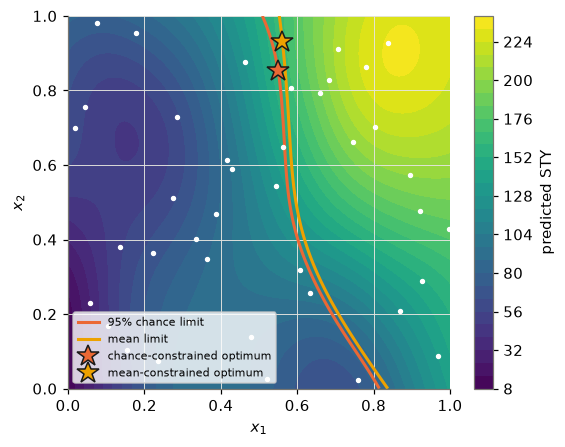

In [13]:
cg = np.linspace(0, 1, 151)
CG = jnp.array(np.stack(np.meshgrid(cg, cg), -1))
fig, ax = plt.subplots(figsize=(5.6, 4.4))
cs = ax.contourf(cg, cg, np.asarray(jax.vmap(jax.vmap(gp_sty.mean))(CG)), levels=30, cmap="viridis")
fig.colorbar(cs, ax=ax, label="predicted STY")
for fun, col, lab in ((chance, ORANGE, "95% chance limit"), (mean_only, YELLOW, "mean limit")):
    ax.contour(cg, cg, np.asarray(jax.vmap(jax.vmap(fun))(CG)), levels=[0], colors=col, linewidths=2)
    ax.plot([], [], color=col, lw=2, label=lab)
ax.plot(*Xc.T, ".", color="white", ms=5)
ax.plot(*rc.x, "*", color=ORANGE, ms=15, mec=INK, label="chance-constrained optimum")
ax.plot(*rm.x, "*", color=YELLOW, ms=15, mec=INK, label="mean-constrained optimum")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.legend(fontsize=7, loc="lower left")
plt.show()

## 4. Bayesian optimization with a global acquisition step

Finally, a short Bayesian-optimization loop on peaks: start from 8 points,
and at every step refit the GP and add the point that maximizes EI, with
branch and bound limited to 60 s per step. Each step is a new GP with one
more point, so each step also compiles new kernels. The table records the
EI found and the proven upper bound on EI, so the remaining gap of each
step is visible.

In [14]:
Xb = lhs(8, seed=3)
yb = np.asarray(peaks(Xb))
log = []
for it in range(8):
    gpb = GP(Xb, yb, LO, HI)
    fb = float(yb.min())

    def neg_ei_b(x, gpb=gpb, fb=fb):
        return -expected_improvement(gpb.mean(x), gpb.std(x), fb)

    r, t = solve(neg_ei_b, LO, HI, time_limit=60)
    ynew = float(peaks(r.x))
    log.append(dict(iteration=it + 1, N=len(yb), status=r.status, EI_found=-r.fun, EI_bound=-r.lower_bound,
                    x1=r.x[0], x2=r.x[1], y_new=ynew, best_so_far=min(fb, ynew), time_s=t))
    Xb, yb = np.vstack([Xb, r.x]), np.append(yb, ynew)
bo = pd.DataFrame(log)
bo

,iteration,N,status,EI_found,EI_bound,x1,x2,y_new,best_so_far,time_s
0,1,8,optimal,0.243739,0.244739,-1.809799,-0.279023,-1.574672,-1.574672,6.894614
1,2,9,optimal,0.132172,0.133151,3.000000,-0.238146,0.031612,-1.574672,7.343222
2,3,10,optimal,0.177810,0.178753,-1.821728,-1.003830,-0.082794,-1.574672,8.047914
3,4,11,optimal,0.193942,0.194903,-3.000000,-0.333725,-0.030813,-1.574672,9.808575
4,5,12,optimal,0.183329,0.184327,-1.720156,0.107272,-2.291937,-2.291937,8.662012
5,6,13,optimal,0.153616,0.154607,-1.705473,0.476963,-2.022673,-2.291937,9.333546
6,7,14,optimal,0.059632,0.060630,-1.523527,0.176804,-2.850540,-2.850540,10.266700
7,8,15,optimal,0.129441,0.130434,-1.312941,0.370457,-2.926200,-2.926200,9.173323


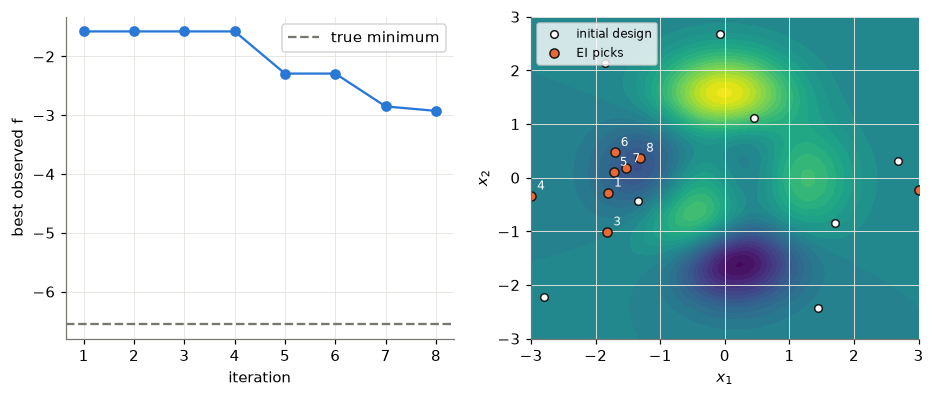

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(bo.iteration, bo.best_so_far, "o-", color=BLUE)
axes[0].axhline(-6.551, color=MUTED, ls="--", label="true minimum")
axes[0].set_xlabel("iteration")
axes[0].set_ylabel("best observed f")
axes[0].legend()
axes[1].contourf(gg, gg, np.asarray(peaks(G2)), levels=30, cmap="viridis")
axes[1].plot(*Xb[:8].T, "o", color="white", mec=INK, ms=5, label="initial design")
axes[1].plot(*Xb[8:].T, "o", color=ORANGE, mec=INK, ms=6, label="EI picks")
for i, p in enumerate(Xb[8:]):
    axes[1].annotate(str(i + 1), p, xytext=(4, 4), textcoords="offset points", color="white", fontsize=8)
axes[1].legend(fontsize=8, loc="upper left")
axes[1].set_xlabel("$x_1$")
axes[1].set_ylabel("$x_2$")
plt.show()

All eight steps are certified, each in about 7 to 10 s including
compilation for the new GP size (`EI_bound` is within $10^{-3}$ of
`EI_found`). With the `jnp` formulas none was certified in 60 s, and with
the kernel primitives alone, four. After 8 steps the best value is −2.93,
against −6.55 for the true minimum: EI explores the large unexplored
regions first.

## Summary

A trained GP written in `jax.numpy` is a reduced-space model for jaxglobal
with no extra work: no auxiliary variables per training point, no
equality constraints, no hand-written GAMS or Pyomo expressions with
thousands of terms. What makes it work well is relaxing each piece as what
it is: the kernels from `jaxglobal.kernels`, relaxed by the envelopes of
[schweidtmann2021deterministic]; `jaxglobal.gp.gp_std`, whose relaxation
uses the GP's own structure; and the EI and PI primitives, relaxed from
their convexity and monotonicity. With them every problem here is
certified to a $10^{-3}$ gap: GP means with up to 400 training points
(18 s), all four kernels, LCB, EI and PI (with and without a margin), a
chance constraint built from a second GP's standard deviation, and every
step of the Bayesian-optimization loop.

What is still missing:

* The integer number of layers in the paper's membrane case has no
  counterpart, since jaxglobal has no integer variables. For a small
  integer range one would solve one continuous problem per value.
* `gp_std`'s lower bound is constant on each box. A convex, non-constant
  one would tighten EI and PI further.

The node counts are driven by relaxation quality, not by the search: with
the `jnp` formulas the same problems needed 8 to 27 times more nodes, and
the chance constraint, PI without a margin and the Bayesian-optimization
steps did not close.